Assignement02

In [67]:
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
import powerlaw
import tailestim
import warnings
import logging
from pathlib import Path

1.

(a)

In [59]:
def grow_ba_network(N=10_000, m=4, seed=42):
    rng = np.random.default_rng(seed)
    G = nx.complete_graph(m)
    checkpoints = {100, 1000, 10_000}
    degree_sequences = {}

    while G.number_of_nodes() < N:
        new_node = G.number_of_nodes()
        nodes = np.array(G.nodes())
        degrees = np.array([G.degree(node) for node in nodes], dtype=float)

        # Choose m different nodes with probability proportional to degree.
        targets = rng.choice(
            nodes, size=m, replace=False, p=degrees / degrees.sum()
        )
        for target in targets:
            G.add_edge(new_node, int(target))

        if G.number_of_nodes() in checkpoints:
            degree_sequences[G.number_of_nodes()] = [
                degree for _, degree in G.degree()
            ]

    return G, degree_sequences

In [60]:
G_ba, degree_sequences = grow_ba_network()

In [61]:
for n, degrees in degree_sequences.items():
    print(f"N = {n}: saved {len(degrees)} degrees")

N = 100: saved 100 degrees
N = 1000: saved 1000 degrees
N = 10000: saved 10000 degrees


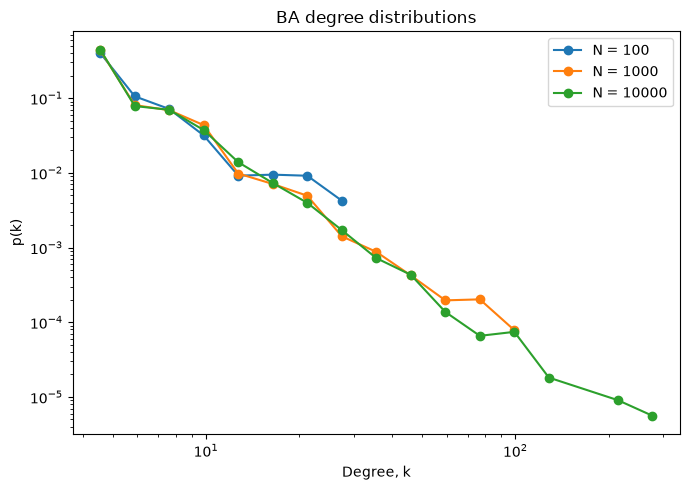

In [62]:
max_degree = max(max(degrees) for degrees in degree_sequences.values())
bins = np.logspace(np.log10(4), np.log10(max_degree + 1), 18)

plt.figure(figsize=(7, 5))
for n, degrees in degree_sequences.items():
    probability, edges = np.histogram(degrees, bins=bins, density=True)
    centers = np.sqrt(edges[:-1] * edges[1:])
    nonzero = probability > 0
    plt.loglog(
        centers[nonzero], probability[nonzero], "o-", label=f"N = {n}"
    )

plt.xlabel("Degree, k")
plt.ylabel("p(k)")
plt.title("BA degree distributions")
plt.legend()
plt.tight_layout()
plt.show()

(b)

/Users/yujiaao/miniforge3/envs/network-assignment/lib/python3.12/site-packages/powerlaw/distributions.py:743: OptimizeWarning: Initial guess is not within the specified bounds
  result = scipy.optimize.minimize(fit_function,
/Users/yujiaao/miniforge3/envs/network-assignment/lib/python3.12/site-packages/powerlaw/distributions.py:743: OptimizeWarning: Initial guess is not within the specified bounds
  result = scipy.optimize.minimize(fit_function,


N=100: gamma=2.77, k_min=5
N=1000: gamma=2.70, k_min=4
N=10000: gamma=2.89, k_min=10


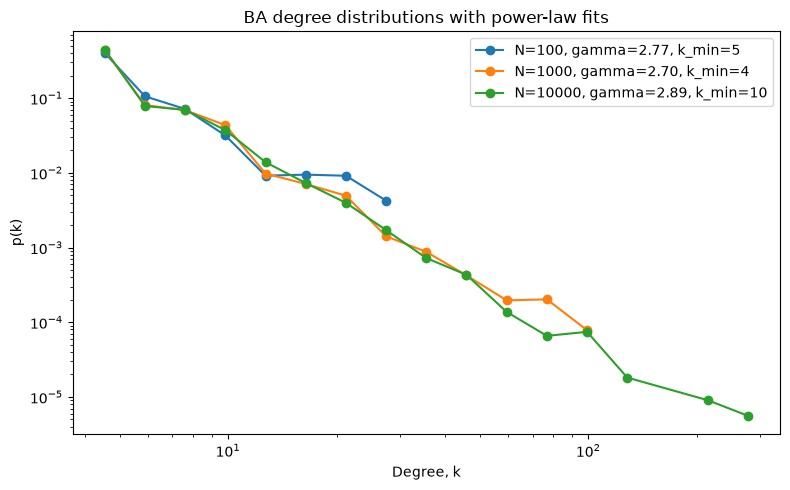

In [68]:
max_degree = max(max(degrees) for degrees in degree_sequences.values())
bins = np.logspace(np.log10(4), np.log10(max_degree + 1), 18)

plt.figure(figsize=(8, 5))
for n, degrees in degree_sequences.items():
    fit = powerlaw.Fit(degrees, discrete=True, verbose=False)
    gamma_hat = fit.power_law.alpha
    k_min = fit.power_law.xmin

    probability, edges = np.histogram(degrees, bins=bins, density=True)
    centers = np.sqrt(edges[:-1] * edges[1:])
    nonzero = probability > 0

    label = f"N={n}, gamma={gamma_hat:.2f}, k_min={k_min:.0f}"
    plt.loglog(centers[nonzero], probability[nonzero], "o-", label=label)
    print(f"N={n}: gamma={gamma_hat:.2f}, k_min={k_min:.0f}")

plt.xlabel("Degree, k")
plt.ylabel("p(k)")
plt.title("BA degree distributions with power-law fits")
plt.legend()
plt.tight_layout()
plt.show()

The estimates are approximately $2.77$, $2.70$, and $2.89$ for $N=10^2,10^3,$ and $10^4$. They do not approach 3 monotonically, but the largest network gives the closest estimate.

The exact distribution

$$p_k=\frac{2m(m+1)}{k(k+1)(k+2)}$$

only behaves like $k^{-3}$ for large $k$. Small networks have few observations in this tail, so their estimates fluctuate. As the network grows, more tail data become available and the estimate generally moves closer to 3.

(c)

In [69]:
def grow_ba_degrees_fast(N=10_000, m=4, seed=0):
    """Grow a BA network and return its degree sequence."""
    rng = np.random.default_rng(seed)
    G = nx.complete_graph(m)

    # A node appears once per edge, so sampling this list is degree-proportional.
    repeated_nodes = []
    for node, degree in G.degree():
        repeated_nodes.extend([node] * degree)

    for new_node in range(m, N):
        targets = set()
        while len(targets) < m:
            index = rng.integers(len(repeated_nodes))
            targets.add(repeated_nodes[index])

        G.add_edges_from((new_node, target) for target in targets)
        repeated_nodes.extend(targets)
        repeated_nodes.extend([new_node] * m)

    return np.array([degree for _, degree in G.degree()])

In [70]:
estimates = {
    "powerlaw": [],
    "Hill": [],
    "Moments": [],
    "Kernel": [],
}
likelihood_tests = []

warnings.filterwarnings("ignore")
logging.disable(logging.WARNING)

for seed in range(100):
    degrees = grow_ba_degrees_fast(seed=seed)

    fit = powerlaw.Fit(degrees, discrete=True, verbose=False)
    estimates["powerlaw"].append(fit.power_law.alpha)
    likelihood_tests.append(
        fit.distribution_compare("power_law", "lognormal")
    )

    for name, estimator_class in [
        ("Hill", tailestim.HillEstimator),
        ("Moments", tailestim.MomentsEstimator),
        ("Kernel", tailestim.KernelTypeEstimator),
    ]:
        estimator = estimator_class(base_seed=seed, verbose=False)
        estimator.fit(degrees)
        estimates[name].append(estimator.get_result().gamma_)

    if (seed + 1) % 10 == 0:
        print(f"Finished {seed + 1}/100 networks")

logging.disable(logging.NOTSET)
warnings.resetwarnings()

Finished 10/100 networks
Finished 20/100 networks
Finished 30/100 networks
Finished 40/100 networks
Finished 50/100 networks
Finished 60/100 networks
Finished 70/100 networks
Finished 80/100 networks
Finished 90/100 networks
Finished 100/100 networks


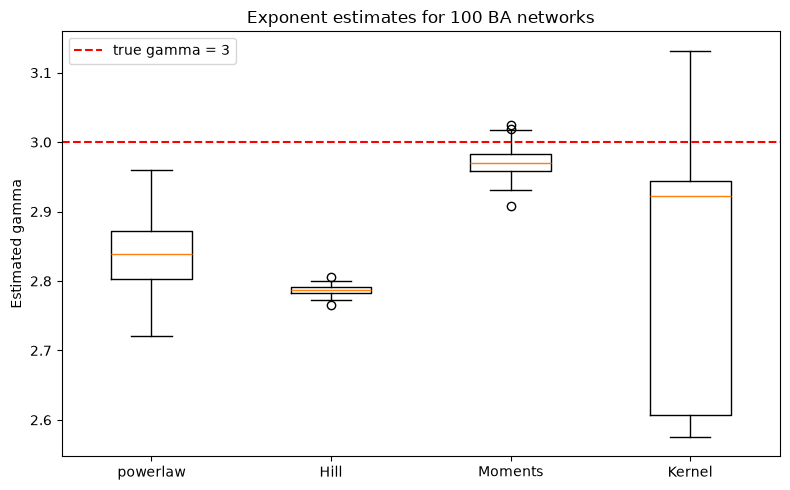

powerlaw: mean=2.838, std=0.049
Hill: mean=2.787, std=0.006
Moments: mean=2.972, std=0.020
Kernel: mean=2.832, std=0.174
Power law significantly favored: 0
Lognormal significantly favored: 2
Inconclusive: 98


In [71]:
plt.figure(figsize=(8, 5))
plt.boxplot(
    list(estimates.values()), tick_labels=list(estimates.keys())
)
plt.axhline(3, color="red", linestyle="--", label="true gamma = 3")
plt.ylabel("Estimated gamma")
plt.title("Exponent estimates for 100 BA networks")
plt.legend()
plt.tight_layout()
plt.show()

for name, values in estimates.items():
    print(f"{name}: mean={np.mean(values):.3f}, std={np.std(values, ddof=1):.3f}")

R, p = map(np.array, zip(*likelihood_tests))
print("Power law significantly favored:", np.sum((R > 0) & (p < 0.05)))
print("Lognormal significantly favored:", np.sum((R < 0) & (p < 0.05)))
print("Inconclusive:", np.sum(p >= 0.05))

The ensemble results were:

- `powerlaw`: mean $=2.838$, standard deviation $=0.049$
- Hill: mean $=2.787$, standard deviation $=0.006$
- Moments: mean $=2.972$, standard deviation $=0.020$
- Kernel: mean $=2.832$, standard deviation $=0.174$

The moments estimator comes closest to the true value $\gamma=3$. The other three are biased downward for networks of this finite size, and the kernel estimator also has the largest spread.

The likelihood-ratio test significantly favored the power law in 0 networks and the lognormal in 2 networks; 98 comparisons were inconclusive. Thus, even for networks generated by preferential attachment, finite samples usually do not provide enough evidence to distinguish a power law from a lognormal.

(d)

Broido and Clauset define a scale-free network using a relatively strict pure power-law fit. They estimate $k_{min}$ and $\gamma$, test goodness of fit, and compare the power law with alternatives such as a lognormal. Voitalov et al. instead define scale-free distributions by regular variation, which allows deviations from a pure power law at finite degrees. They estimate the tail exponent using the Hill, moments, and kernel methods.

This difference explains their conclusions: the first method rejects many imperfect power laws, while the second accepts distributions with an asymptotic power-law tail. Our BA networks would be scale-free under the regular-variation definition. They also receive reasonable support under Broido and Clauset's approach because almost none of the likelihood-ratio tests significantly favored the lognormal. I prefer regular variation because it includes finite-size effects and the exact BA degree distribution.

2.

In [48]:
DATA = Path("soc-hamsterster.edges")
OUT = Path("results")
OUT.mkdir(exist_ok=True)
SEED = 42

# Use a unique name so this graph is not confused with G from earlier questions.
G_community = nx.read_edgelist(
    DATA, comments="%", nodetype=int, data=False, create_using=nx.Graph()
)
print(G_community.number_of_nodes(), "nodes")
print(G_community.number_of_edges(), "edges")

2426 nodes
16630 edges


(a)

In [49]:
from networkx.algorithms.community import louvain_communities
from networkx.algorithms.community.quality import modularity

communities_a = louvain_communities(
    G_community, weight=None, resolution=1, seed=SEED
)
communities_a = sorted(communities_a, key=lambda c: (-len(c), min(c)))

partition_a = {
    node: community_id
    for community_id, community in enumerate(communities_a)
    for node in community
}
Q_a = modularity(G_community, communities_a, weight=None, resolution=1)

print(f"Modularity: {Q_a:.6f}")
print("Number of communities:", len(communities_a))
print("Partition sample:", dict(list(partition_a.items())[:10]))

Modularity: 0.563420
Number of communities: 174
Partition sample: {11: 0, 12: 0, 1078: 0, 70: 0, 71: 0, 72: 0, 73: 0, 86: 0, 87: 0, 88: 0}


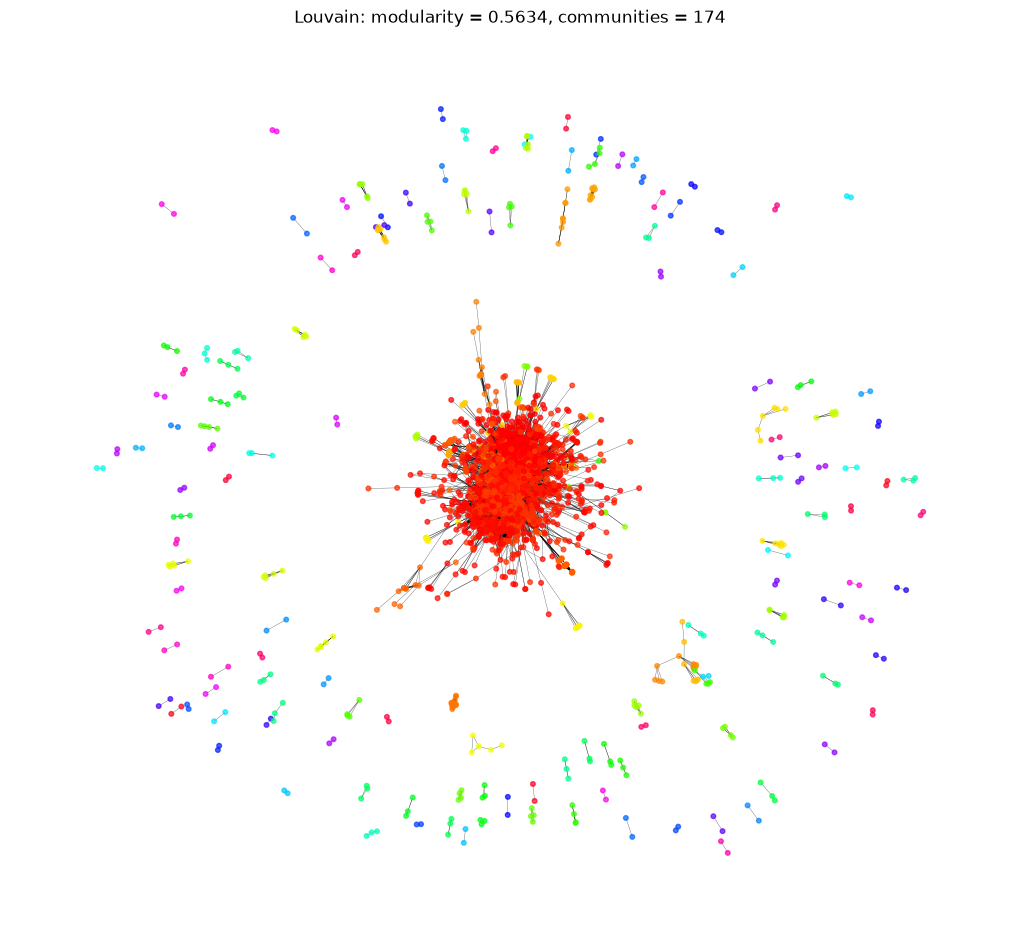

In [50]:
nodes = list(G_community.nodes())
pos = nx.spring_layout(
    G_community, seed=SEED, iterations=30, weight=None, method="force"
)

plt.figure(figsize=(10, 9))
nx.draw(
    G_community, pos,
    nodelist=nodes,
    node_color=[partition_a[node] for node in nodes],
    cmap=plt.cm.hsv,
    node_size=11,
    width=0.25,
    alpha=0.7,
    with_labels=False,
)
plt.title(
    f"Louvain: modularity = {Q_a:.4f}, communities = {len(communities_a)}"
)
plt.axis("off")
plt.savefig(OUT / "a_louvain.png", dpi=220, bbox_inches="tight")
plt.show()

(b)

Number of communities (SBM): 74
Dictionary sample: {1: 2380, 2: 1375, 3: 1375, 4: 1353, 5: 1353, 6: 1353, 7: 1353, 8: 1353, 11: 931, 1308: 2380}


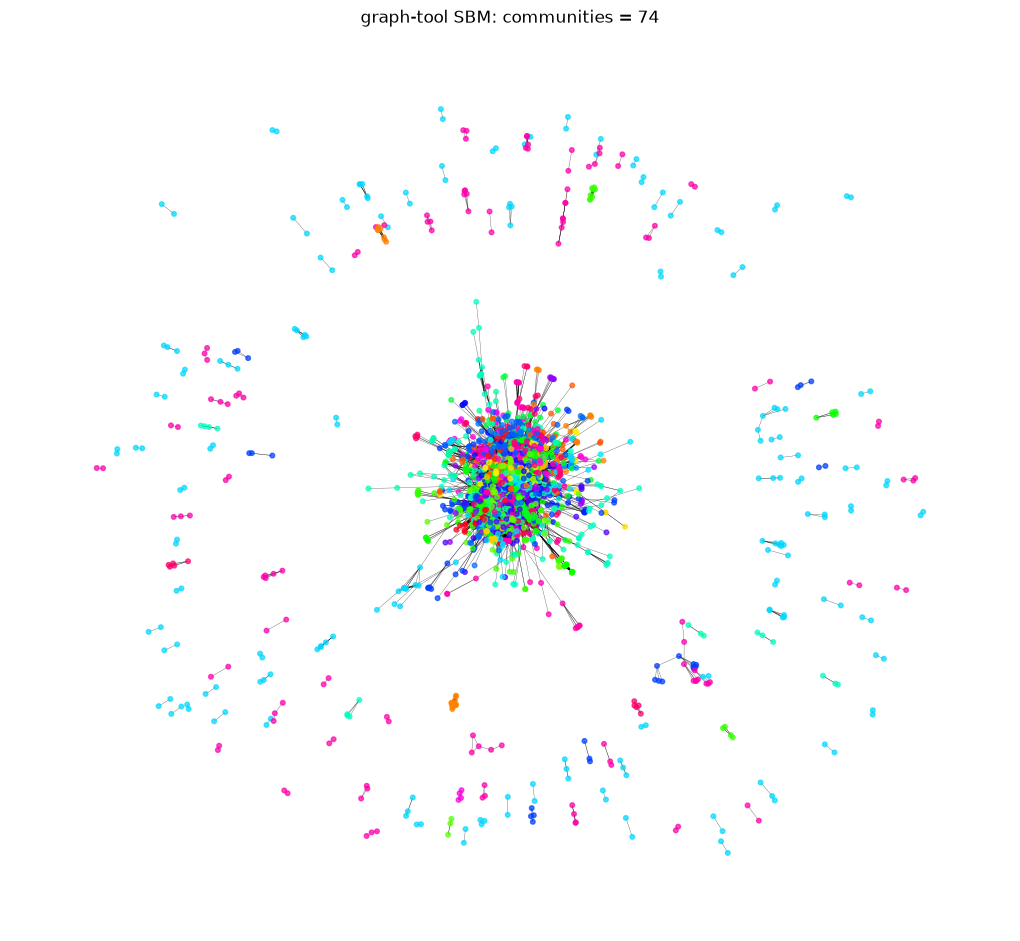

In [51]:
import graph_tool.all as gt
gt.seed_rng(42)
gt.openmp_set_num_threads(1)

def nx_to_gt(G):
    # Simplified Class 09 converter for this unweighted integer-ID graph.
    g = gt.Graph(directed=False)
    original_id = g.new_vertex_property('int64_t')
    node_to_vertex = {}
    for node in G.nodes():
        v = g.add_vertex()
        node_to_vertex[node] = v
        original_id[v] = node
    for u, v in G.edges():
        g.add_edge(node_to_vertex[u], node_to_vertex[v])
    g.vp['id'] = original_id
    return g

g = nx_to_gt(G_community)
assert g.num_vertices() == G_community.number_of_nodes()
assert g.num_edges() == G_community.number_of_edges()
state = gt.minimize_blockmodel_dl(g, state_args=dict(deg_corr=True))
blocks = state.get_blocks()
partition_b = {int(g.vp['id'][v]): int(blocks[v]) for v in g.vertices()}
print('Number of communities (SBM):', len(set(partition_b.values())))
print('Dictionary sample:', dict(list(partition_b.items())[:10]))

# Reuse the same node order and layout as in part (a).
plt.figure(figsize=(10, 9))
nx.draw(
    G_community, pos,
    nodelist=nodes,
    node_color=[partition_b[node] for node in nodes],
    cmap=plt.cm.hsv,
    node_size=11,
    width=0.25,
    alpha=0.7,
    with_labels=False,
)
plt.title(f'graph-tool SBM: communities = {len(set(partition_b.values()))}')
plt.axis('off')
plt.savefig(OUT / 'b_graph_tool.png', dpi=220, bbox_inches='tight')
plt.show()


（c）

In [52]:
# 1. Create a degree-preserving randomized graph
G_random = G_community.copy()
m = G_random.number_of_edges()

nx.double_edge_swap(
    G_random,
    nswap=10 * m,
    max_tries=100 * m,
    seed=SEED
)

# Verify that node IDs, edge count, and every node's degree are preserved
assert set(G_random.nodes()) == set(G_community.nodes())
assert G_random.number_of_edges() == G_community.number_of_edges()
assert dict(G_random.degree()) == dict(G_community.degree())

print("Number of nodes:", G_random.number_of_nodes())
print("Number of edges:", G_random.number_of_edges())
print("All node degrees are preserved.")


# 2. Run Louvain on the randomized graph
communities_random_a = louvain_communities(
    G_random,
    weight=None,
    resolution=1,
    seed=42
)

partition_random_a = {
    node: community_id
    for community_id, community in enumerate(communities_random_a)
    for node in community
}

Q_random_a = modularity(
    G_random,
    communities_random_a,
    weight=None,
    resolution=1
)

print(f"Randomized Louvain modularity: {Q_random_a:.6f}")
print(
    "Randomized Louvain communities:",
    len(set(partition_random_a.values()))
)


# 3. Run graph-tool SBM on the same randomized graph
g_random = nx_to_gt(G_random)

gt.seed_rng(42)
gt.openmp_set_num_threads(1)

state_random = gt.minimize_blockmodel_dl(
    g_random,
    state_args=dict(deg_corr=True)
)

blocks_random = state_random.get_blocks()

# Use the original node IDs stored by nx_to_gt()
partition_random_b = {
    int(g_random.vp["id"][v]): int(blocks_random[v])
    for v in g_random.vertices()
}

print(
    "Randomized SBM communities:",
    len(set(partition_random_b.values()))
)


# 4. Verify that both partitions contain every original node
assert set(partition_random_a) == set(G_community.nodes())
assert set(partition_random_b) == set(G_community.nodes())

print("Louvain partition sample:",
      dict(list(partition_random_a.items())[:10]))
print("SBM partition sample:",
      dict(list(partition_random_b.items())[:10]))

Number of nodes: 2426
Number of edges: 16630
All node degrees are preserved.
Randomized Louvain modularity: 0.215134
Randomized Louvain communities: 15
Randomized SBM communities: 1
Louvain partition sample: {1027: 0, 774: 0, 1528: 0, 2058: 0, 1806: 0, 15: 0, 1552: 0, 1298: 0, 21: 0, 533: 0}
SBM partition sample: {1: 0, 2: 0, 3: 0, 4: 0, 5: 0, 6: 0, 7: 0, 8: 0, 11: 0, 1308: 0}


(d)

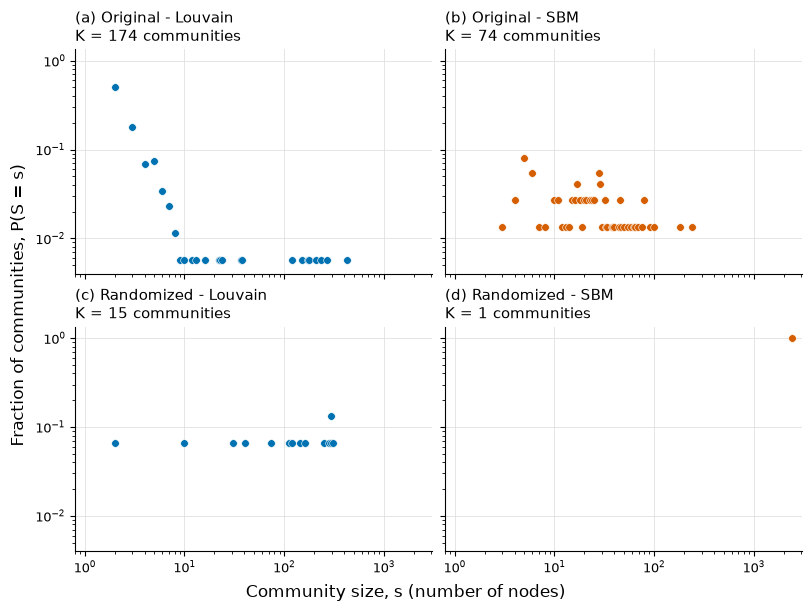

In [73]:
partitions = {
    "Original - Louvain": partition_a,
    "Original - SBM": partition_b,
    "Randomized - Louvain": partition_random_a,
    "Randomized - SBM": partition_random_b,
}

# Verify that all partitions cover the same nodes
node_set = set(partition_a)
assert node_set, "Partitions must not be empty."
assert all(set(p) == node_set for p in partitions.values())

# Count the number of nodes in each community
size_data = {
    name: np.unique(list(p.values()), return_counts=True)[1]
    for name, p in partitions.items()
}

max_size = max(sizes.max() for sizes in size_data.values())
max_communities = max(len(sizes) for sizes in size_data.values())

output_dir = Path("results")
output_dir.mkdir(exist_ok=True)

style = {
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.linewidth": 0.8,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "pdf.fonttype": 42,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
}

with plt.rc_context(style):
    fig, axes = plt.subplots(
        2, 2,
        figsize=(8, 6),
        sharex=True,
        sharey=True,
        constrained_layout=True
    )

    colors = ["#0072B2", "#D55E00", "#0072B2", "#D55E00"]

    for i, (ax, (name, sizes), color) in enumerate(
        zip(axes.flat, size_data.items(), colors)
    ):
        s, counts = np.unique(sizes, return_counts=True)
        probability = counts / len(sizes)

        ax.scatter(
            s, probability,
            s=30,
            color=color,
            edgecolors="white",
            linewidths=0.4,
            zorder=3
        )

        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlim(0.8, 1.25 * max_size)
        ax.set_ylim(0.7 / max_communities, 1.35)

        ax.set_title(
            f"({chr(97 + i)}) {name}\n"
            f"K = {len(sizes):,} communities",
            loc="left"
        )

        ax.grid(
            True, which="major",
            color="0.88", linewidth=0.6
        )
        ax.set_axisbelow(True)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.tick_params(which="both", direction="out")

    fig.supxlabel("Community size, s (number of nodes)")
    fig.supylabel("Fraction of communities, P(S = s)")

    fig.savefig(
        output_dir / "community_size_distributions.pdf",
        bbox_inches="tight"
    )
    fig.savefig(
        output_dir / "community_size_distributions.png",
        dpi=600,
        bbox_inches="tight"
    )

    plt.show()

(e)

I would compare the partitions using **variation of information (VI)** (Meilă, 2007). For two partitions $b_1$ and $b_2$ of the same nodes,

$$VI(b_1,b_2)=H(b_1)+H(b_2)-2I(b_1;b_2),$$

where $H$ is entropy and $I$ is mutual information. A smaller VI means that the partitions are more similar: VI is 0 when they are identical, even if their community ID numbers are different.

A useful comparison function should:

- be unchanged if community labels are renamed;
- be symmetric, so $f(b_1,b_2)=f(b_2,b_1)$;
- give 0 only for identical partitions;
- work when the numbers and sizes of communities differ;
- satisfy the triangle inequality if it is used as a distance.

VI has all of these metric properties. Because the four dictionaries contain the same node set, I could calculate VI for each pair and present the six values in a pairwise comparison matrix. If comparisons across networks of different sizes were needed, I would use a normalized version of VI.

Reference: Meilă, M. (2007). [Comparing clusterings—an information based distance](https://doi.org/10.1016/j.jmva.2006.11.013). *Journal of Multivariate Analysis*, 98(5), 873–895.

3.

(a)

The LFR benchmark was introduced because older benchmarks used nearly equal node degrees and equal-sized communities, unlike many real networks. Its main contribution is a more realistic test in which both node degrees and community sizes follow power-law distributions.

The main inputs are the number of nodes $N$, average and maximum degree, degree exponent $\gamma$, community-size exponent $\beta$, minimum and maximum community sizes, and mixing parameter $\mu$. The parameter $\mu$ is the fraction of each node's edges that go outside its community, so larger $\mu$ makes communities harder to detect.

The output is a synthetic graph together with its planted community labels. Because the true partition is known, a detected partition can be compared with the ground truth. The paper also uses the benchmark to reveal limitations of modularity optimization and Potts-model clustering that simpler benchmarks may miss.

(b)

**i-ii. Degree sequence and mixing parameter**

In [54]:
def powerlaw_degrees(n, gamma, average_degree, seed=42):
    """Generate an integer power-law degree sequence."""
    if n < 2 or gamma <= 1 or not 1 <= average_degree < n:
        raise ValueError("Use n >= 2, gamma > 1, and 1 <= average_degree < n")

    rng = np.random.default_rng(seed)
    degrees = rng.zipf(gamma, n).astype(float)
    degrees *= average_degree / degrees.mean()
    degrees = np.clip(np.rint(degrees), 1, n - 1).astype(int)

    # Match the requested mean and make the degree sum even.
    target = int(round(n * average_degree))
    target += target % 2
    difference = target - degrees.sum()

    while difference != 0:
        step = 1 if difference > 0 else -1
        choices = np.where(degrees < n - 1)[0] if step == 1 else np.where(degrees > 1)[0]
        degrees[rng.choice(choices)] += step
        difference -= step

    return degrees.tolist()


def split_degrees(degrees, mu):
    """Split each degree into internal and external parts."""
    if not 0 <= mu <= 1:
        raise ValueError("mu must be between 0 and 1")

    degrees = np.asarray(degrees, dtype=int)
    k_in = np.rint(degrees * (1 - mu)).astype(int)
    k_out = degrees - k_in
    return k_in.tolist(), k_out.tolist()

In [55]:
# Example
n = 1000
gamma = 2.5
average_degree = 20
mu = 0.3

degree_sequence = powerlaw_degrees(n, gamma, average_degree)
k_in, k_out = split_degrees(degree_sequence, mu)

print("Number of degrees:", len(degree_sequence))
print("Average degree:", np.mean(degree_sequence))
print("Even degree sum:", sum(degree_sequence) % 2 == 0)
print("First 10 total degrees:", degree_sequence[:10])
print("First 10 internal degrees:", k_in[:10])
print("First 10 external degrees:", k_out[:10])

Number of degrees: 1000
Average degree: 20.0
Even degree sum: True
First 10 total degrees: [24, 14, 31, 20, 10, 67, 23, 24, 10, 14]
First 10 internal degrees: [17, 10, 22, 14, 7, 47, 16, 17, 7, 10]
First 10 external degrees: [7, 4, 9, 6, 3, 20, 7, 7, 3, 4]


**iii. Additional considerations for community sizes**

The community sizes also follow a power law, but they must sum exactly to $N$. The bounds must satisfy $s_{min}>k_{min}$ and $s_{max}>k_{max}$ so that every node can fit into at least one community.

(c)

**Testing the convergence of `nx.LFR_benchmark_graph()`**

In [56]:
# Try each parameter set with three different random seeds.
parameter_sets = {
    "baseline": dict(tau1=2.5, tau2=1.5, mu=0.3,
                     average_degree=15, min_community=20),
    "low mu": dict(tau1=2.5, tau2=1.5, mu=0.1,
                   average_degree=15, min_community=20),
    "many small communities": dict(tau1=2.5, tau2=2.0, mu=0.3,
                                   average_degree=15, min_community=10),
    "larger communities": dict(tau1=2.5, tau2=1.5, mu=0.3,
                               average_degree=15, min_community=50),
}

for name, parameters in parameter_sets.items():
    successes = 0
    for seed in range(3):
        try:
            nx.LFR_benchmark_graph(
                n=250, **parameters, max_iters=100, seed=seed
            )
            successes += 1
        except nx.ExceededMaxIterations:
            pass

    print(f"{name}: {successes}/3 successful runs")

baseline: 1/3 successful runs
low mu: 0/3 successful runs
many small communities: 0/3 successful runs
larger communities: 2/3 successful runs


**Results and explanation**

The success rates were 1/3 for the baseline, 0/3 for low $\mu$, 0/3 for many small communities, and 2/3 for larger communities.

Low $\mu$ gives nodes more internal edges, so high-degree nodes need larger communities. Many small communities make this requirement harder to satisfy. The LFR algorithm must match the degree sequence, community sizes, and $\mu$ at the same time. Some random combinations are incompatible, so convergence also changes with the random seed.

4.

(b)

https://github.com/jiaao-yu/network-science-toolkit/blob/main/README.md

(d)

In [75]:
%pip install git+https://github.com/jiaao-yu/network-science-toolkit.git

/Users/yujiaao/miniforge3/envs/network-assignment/lib/python3.12/pty.py:95: DeprecationWarning: This process (pid=58486) is multi-threaded, use of forkpty() may lead to deadlocks in the child.
  pid, fd = os.forkpty()


  Cloning https://github.com/jiaao-yu/network-science-toolkit.git to /private/var/folders/dz/dqk032hx75n0bq8scqcgfpwm0000gn/T/pip-req-build-3t_h_0a0
  Running command git clone --filter=blob:none --quiet https://github.com/jiaao-yu/network-science-toolkit.git /private/var/folders/dz/dqk032hx75n0bq8scqcgfpwm0000gn/T/pip-req-build-3t_h_0a0
  Resolved https://github.com/jiaao-yu/network-science-toolkit.git to commit b835df21f7a89a52e887f4b5284704acd46b5e47
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for yujia-network-science-toolkit: filename=yujia_network_science_toolkit-0.1.0-py3-none-any.whl size=9937 sha256=355ce7652f26c6159f61678672b5a8f42667b466860a57bf46eacd6349468a74
  Stored in directory: /private/var/folders/dz/dqk032hx75n0bq8scqcgfpwm0000gn/T/pip-ephem-wheel-cache-six_cyrm/wheels/30/69/85/d82abbeaa3674bc1051af063f693742af8b463b957585b7b06
Successfully built yujia-network-s

In [76]:
from network_toolkit import (
    degree_distribution,
    all_shortest_from,
    closeness_centrality_from_scratch,
    eigenvector_centrality_from_scratch,
    calculate_modularity,
    girvan_newman,
)

print("Package installed and imported successfully.")

Package installed and imported successfully.
